# Oral Disease Image Classification — Custom CNN (Kaggle)

This notebook classifies six oral/dental image classes using a **custom Convolutional Neural Network (CNN)** built from scratch.

Classes:
- Calculus
- Hypodontia
- Mouth ulcer
- Normal
- caries
- tooth discoloration

### Why a custom CNN?
This version does **not** download pretrained ImageNet weights, so it works even when Kaggle Internet access is disabled.

### Pipeline
1. Load images from the attached Kaggle dataset.
2. Inspect class distribution.
3. Create stratified train/validation/test splits.
4. Handle class imbalance using class weights.
5. Apply image augmentation.
6. Train a custom CNN from scratch.
7. Evaluate with Accuracy, Precision, Recall, F1, Macro-F1, classification report, and confusion matrix.
8. Save the best model and optional TFLite model.


## 1. Setup

The notebook uses packages that are already available in standard Kaggle TensorFlow environments, so no `pip install` cell is normally required.


In [14]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU devices: []


## 2. Configuration

The custom CNN is deliberately kept lightweight for an academic project.

Set `FAST_RUN = True` only when testing the pipeline quickly.


In [15]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

TEST_SIZE = 0.15
VAL_SIZE_FROM_REMAINING = 0.1765   # gives approximately 70/15/15 overall

EPOCHS = 20

FAST_RUN = False
MAX_IMAGES_PER_CLASS_FAST = 100

AUTOTUNE = tf.data.AUTOTUNE


## 3. Locate the Kaggle Dataset

The expected structure is similar to:

```text
/kaggle/input/oral-image-dataset/
└── oral dataset/
    ├── Calculus/
    ├── Hypodontia/
    ├── Mouth ulcer/
    ├── Normal/
    ├── caries/
    └── tooth discoloration/
```

The cell below searches automatically so the notebook remains usable if Kaggle changes the mounted parent path slightly.


In [16]:
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/jhirshaikh/oral-image-dataset/oral dataset"
)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_DIR}")

print("Dataset directory:", DATA_DIR)

print("\nClasses found:")
for class_dir in sorted(DATA_DIR.iterdir()):
    if class_dir.is_dir():
        print(" -", class_dir.name)

Dataset directory: /kaggle/input/datasets/jhirshaikh/oral-image-dataset/oral dataset

Classes found:
 - Calculus
 - Hypodontia
 - Mouth ulcer
 - Normal
 - caries
 - tooth discoloration


## 4. Build the Image DataFrame

In [17]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for class_dir in sorted([p for p in DATA_DIR.iterdir() if p.is_dir()]):
    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "filepath": str(image_path),
                "label": class_dir.name
            })

df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError(f"No image files found under {DATA_DIR}")

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Total images found:", len(df))
print("Classes:", sorted(df["label"].unique()))
display(df.head())


Total images found: 4375
Classes: ['Calculus', 'Hypodontia', 'Mouth ulcer', 'Normal', 'caries', 'tooth discoloration']


,filepath,label
0,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Normal
1,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Calculus
2,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Mouth ulcer
3,/kaggle/input/datasets/jhirshaikh/oral-image-d...,Calculus
4,/kaggle/input/datasets/jhirshaikh/oral-image-d...,tooth discoloration


## 5. Inspect Class Distribution

,image_count
label,
Calculus,1296
Hypodontia,1251
Mouth ulcer,265
Normal,286
caries,219
tooth discoloration,1058


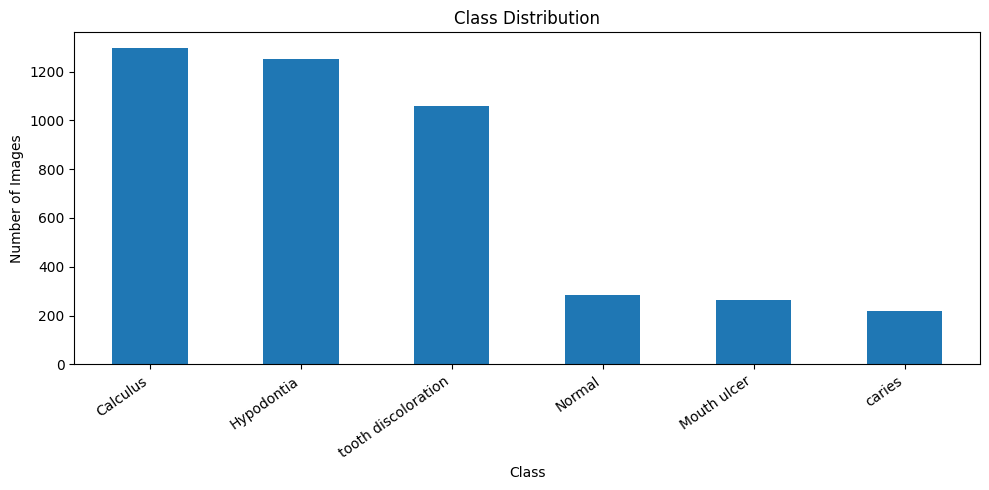

In [18]:
class_counts = df["label"].value_counts().sort_index()
display(class_counts.rename("image_count").to_frame())

plt.figure(figsize=(10, 5))
class_counts.sort_values(ascending=False).plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


### Optional quick-run sampling

This keeps the same classes but limits images per class when `FAST_RUN=True`.


In [19]:
if FAST_RUN:
    df = (
        df.groupby("label", group_keys=False)
          .apply(lambda x: x.sample(min(len(x), MAX_IMAGES_PER_CLASS_FAST), random_state=SEED))
          .reset_index(drop=True)
    )
    print("FAST_RUN enabled.")
    print(df["label"].value_counts())
else:
    print("FAST_RUN disabled. Using all discovered images.")


FAST_RUN disabled. Using all discovered images.


## 6. Encode Labels

In [20]:
class_names = sorted(df["label"].unique())
class_to_index = {name: idx for idx, name in enumerate(class_names)}
index_to_class = {idx: name for name, idx in class_to_index.items()}

df["label_id"] = df["label"].map(class_to_index)

NUM_CLASSES = len(class_names)

print("Class mapping:")
for name, idx in class_to_index.items():
    print(f"{idx}: {name}")


Class mapping:
0: Calculus
1: Hypodontia
2: Mouth ulcer
3: Normal
4: caries
5: tooth discoloration


## 7. Stratified Train / Validation / Test Split

The final proportions are approximately:

- **70% train**
- **15% validation**
- **15% test**

Stratification keeps each class represented in every split.


In [21]:
train_val_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    stratify=df["label_id"],
    random_state=SEED,
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=VAL_SIZE_FROM_REMAINING,
    stratify=train_val_df["label_id"],
    random_state=SEED,
)

print(f"Train:      {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test:       {len(test_df)} ({len(test_df)/len(df):.1%})")

split_summary = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).fillna(0).astype(int)

display(split_summary)


Train:      3061 (70.0%)
Validation: 657 (15.0%)
Test:       657 (15.0%)


,train,validation,test
label,,,
Calculus,908,194,194
Hypodontia,875,188,188
tooth discoloration,740,159,159
Normal,200,43,43
Mouth ulcer,185,40,40
caries,153,33,33


## 8. Compute Class Weights

In [22]:
classes = np.arange(NUM_CLASSES)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_id"].values,
)

class_weights = {int(cls): float(weight) for cls, weight in zip(classes, weights)}

print("Class weights:")
for idx, weight in class_weights.items():
    print(f"{index_to_class[idx]:20s}: {weight:.4f}")


Class weights:
Calculus            : 0.5619
Hypodontia          : 0.5830
Mouth ulcer         : 2.7577
Normal              : 2.5508
caries              : 3.3344
tooth discoloration : 0.6894


## 9. Build TensorFlow Input Pipelines

In [23]:
def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label


def make_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print(train_ds)


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


## 10. Visualize a Training Batch

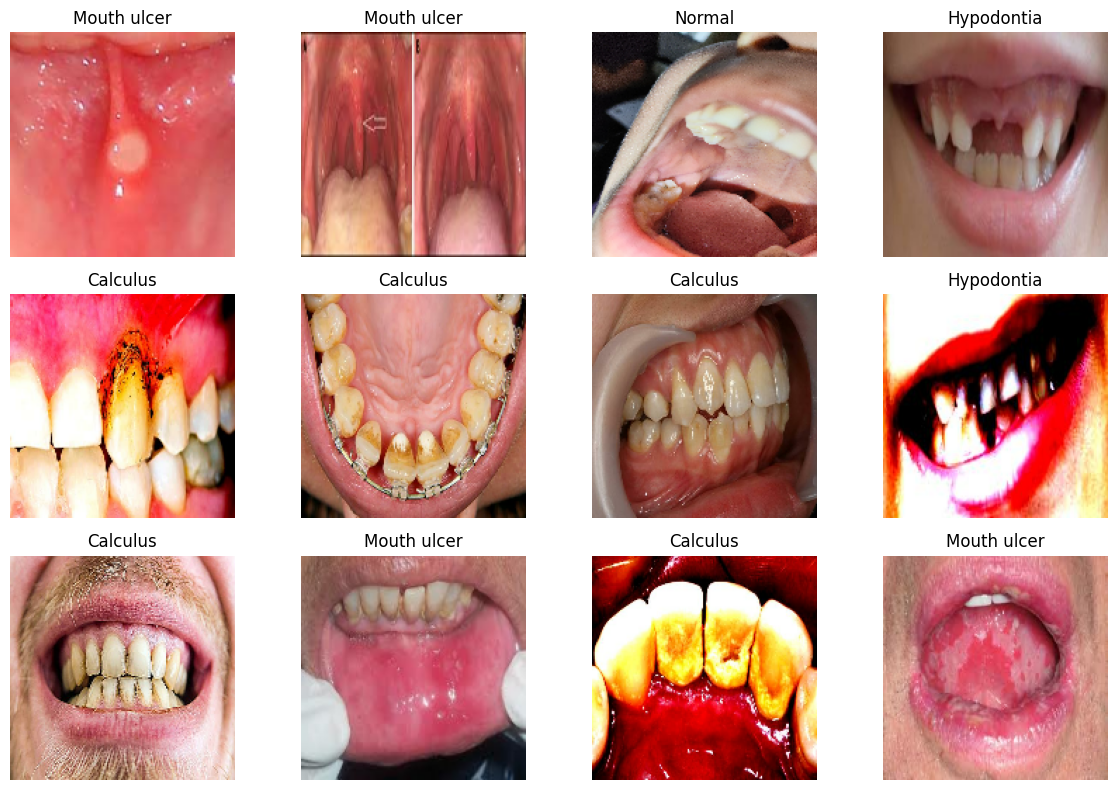

In [24]:
images, labels_batch = next(iter(train_ds))

plt.figure(figsize=(12, 8))
for i in range(min(12, len(images))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(tf.cast(images[i], tf.uint8))
    plt.title(index_to_class[int(labels_batch[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()


## 11. Data Augmentation

Only the training path uses augmentation because augmentation is placed inside the model and is active only during training.


In [25]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ],
    name="data_augmentation",
)


## 12. Build a Custom CNN Model

This model is trained **from scratch**, so no pretrained weights or Internet connection are required.

Architecture:

`Input → Augmentation → Rescaling → Conv blocks → Global Average Pooling → Dense → Dropout → Softmax`


In [26]:
model = keras.Sequential(
    [
        keras.Input(shape=IMG_SIZE + (3,)),

        # Data augmentation
        data_augmentation,

        # Convert image values from [0, 255] to [0, 1]
        layers.Rescaling(1.0 / 255),

        # Block 1
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 2
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 3
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 4
        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Classifier
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.40),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ],
    name="oral_disease_custom_cnn",
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

print(f"Total parameters: {model.count_params():,}")


Model: "oral_disease_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Total parameters: 424,006


## 13. Training Callbacks

The best validation-loss checkpoint is saved automatically. Early stopping helps reduce overfitting.


In [27]:
CHECKPOINT_PATH = "/kaggle/working/best_oral_custom_cnn.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        CHECKPOINT_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]


## 14. Train the Custom CNN

In [28]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
)


Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3518 - loss: 1.7331
Epoch 1: val_loss improved from None to 3.59603, saving model to /kaggle/working/best_oral_custom_cnn.keras

Epoch 1: finished saving model to /kaggle/working/best_oral_custom_cnn.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 193s 2s/step - accuracy: 0.4244 - loss: 1.5393 - val_accuracy: 0.0822 - val_loss: 3.5960 - learning_rate: 0.0010
Epoch 2/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5030 - loss: 1.2825
Epoch 2: val_loss did not improve from 3.59603
96/96 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.5312 - loss: 1.2590 - val_accuracy: 0.0883 - val_loss: 3.6840 - learning_rate: 0.0010
Epoch 3/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5883 - loss: 1.2544
Epoch 3: val_loss did not improve from 3.59603

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
96/96 ━━━━━━━━━━━━━━━━━━━━ 186s 2s/step - accuracy: 0.5861 - loss: 1.1987 - val_accuracy: 0.0639 - val_loss: 4.492

## 15. Plot Training and Validation Curves

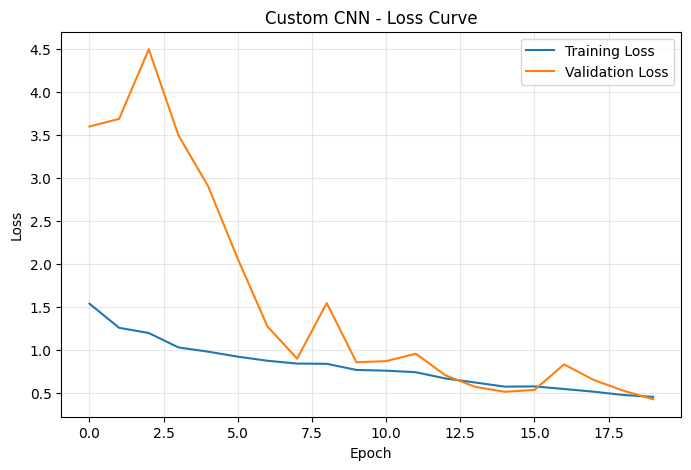

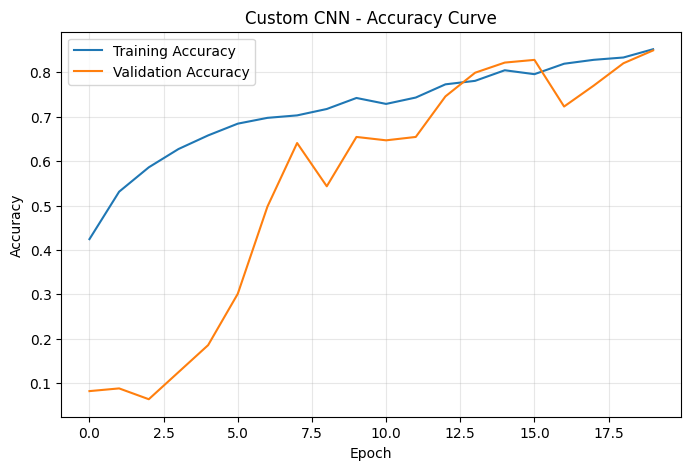

In [29]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.title("Custom CNN - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.title("Custom CNN - Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 16. Simple Overfitting Check

A large gap between training and validation performance can indicate overfitting.


In [30]:
best_train_acc = float(history_df["accuracy"].max())
best_val_acc = float(history_df["val_accuracy"].max())
final_train_acc = float(history_df["accuracy"].iloc[-1])
final_val_acc = float(history_df["val_accuracy"].iloc[-1])

print(f"Best training accuracy:   {best_train_acc:.4f}")
print(f"Best validation accuracy: {best_val_acc:.4f}")
print(f"Final training accuracy:  {final_train_acc:.4f}")
print(f"Final validation accuracy:{final_val_acc:.4f}")
print(f"Final accuracy gap:       {final_train_acc - final_val_acc:.4f}")


Best training accuracy:   0.8520
Best validation accuracy: 0.8493
Final training accuracy:  0.8520
Final validation accuracy:0.8493
Final accuracy gap:       0.0027


In [31]:
# No second fine-tuning stage is needed for a custom CNN trained from scratch.
print("Custom CNN training complete. Proceeding to held-out test evaluation.")


Custom CNN training complete. Proceeding to held-out test evaluation.


## 17. Load the Best Custom CNN Checkpoint

In [32]:
best_model = keras.models.load_model(CHECKPOINT_PATH)
print("Loaded:", CHECKPOINT_PATH)


Loaded: /kaggle/working/best_oral_custom_cnn.keras


## 18. Evaluate on the Held-Out Test Set

The test set is used only after training/model selection.


In [33]:
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 412ms/step - accuracy: 0.8584 - loss: 0.4224
Test loss:     0.4224
Test accuracy: 0.8584


## 19. Accuracy, Precision, Recall, F1, and Macro-F1

In [34]:
y_true = test_df["label_id"].to_numpy()

probabilities = best_model.predict(test_ds, verbose=1)
y_pred = probabilities.argmax(axis=1)

accuracy = accuracy_score(y_true, y_pred)

precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0,
)

metrics_summary = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Weighted Precision",
            "Weighted Recall",
            "Weighted F1",
        ],
        "Score": [
            accuracy,
            precision_macro,
            recall_macro,
            f1_macro,
            precision_weighted,
            recall_weighted,
            f1_weighted,
        ],
    }
)

display(metrics_summary.style.format({"Score": "{:.4f}"}))


21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 424ms/step


,Metric,Score
0,Accuracy,0.8584
1,Macro Precision,0.7738
2,Macro Recall,0.7976
3,Macro F1,0.7787
4,Weighted Precision,0.8655
5,Weighted Recall,0.8584
6,Weighted F1,0.8574


## 20. Per-Class Classification Report

In [35]:
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True,
)

report_df = pd.DataFrame(report).T
display(report_df)


,precision,recall,f1-score,support
Calculus,0.876190,0.948454,0.910891,194.000000
Hypodontia,0.913978,0.904255,0.909091,188.000000
Mouth ulcer,0.645833,0.775000,0.704545,40.000000
Normal,0.706897,0.953488,0.811881,43.000000
caries,0.538462,0.424242,0.474576,33.000000
tooth discoloration,0.961240,0.779874,0.861111,159.000000
accuracy,0.858447,0.858447,0.858447,0.858447
macro avg,0.773767,0.797552,0.778683,657.000000
weighted avg,0.865518,0.858447,0.857370,657.000000


## 21. Confusion Matrix

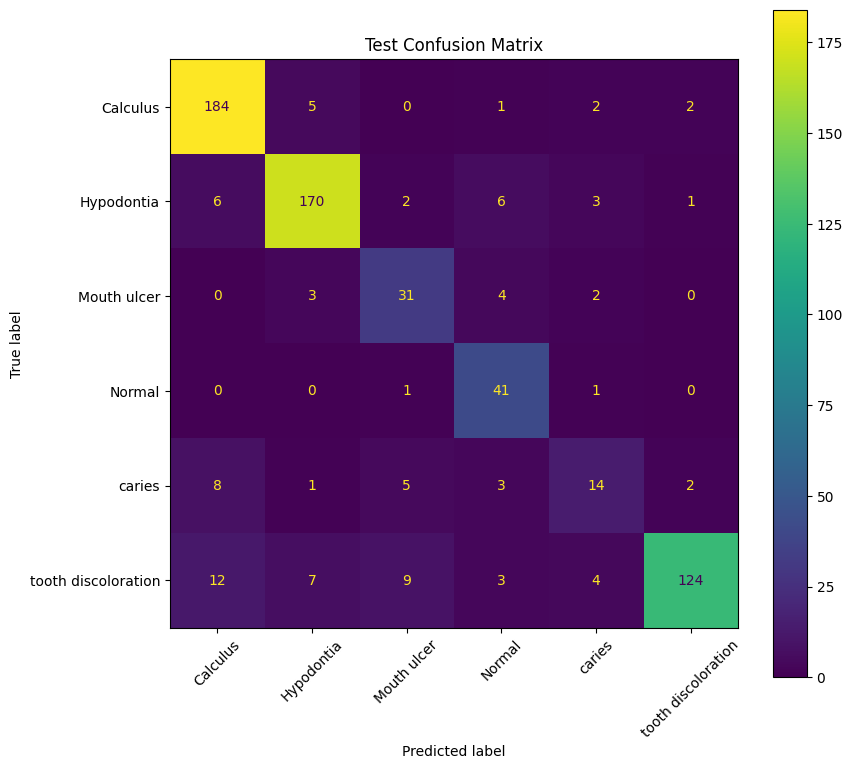

In [36]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
)
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 22. Show Sample Predictions

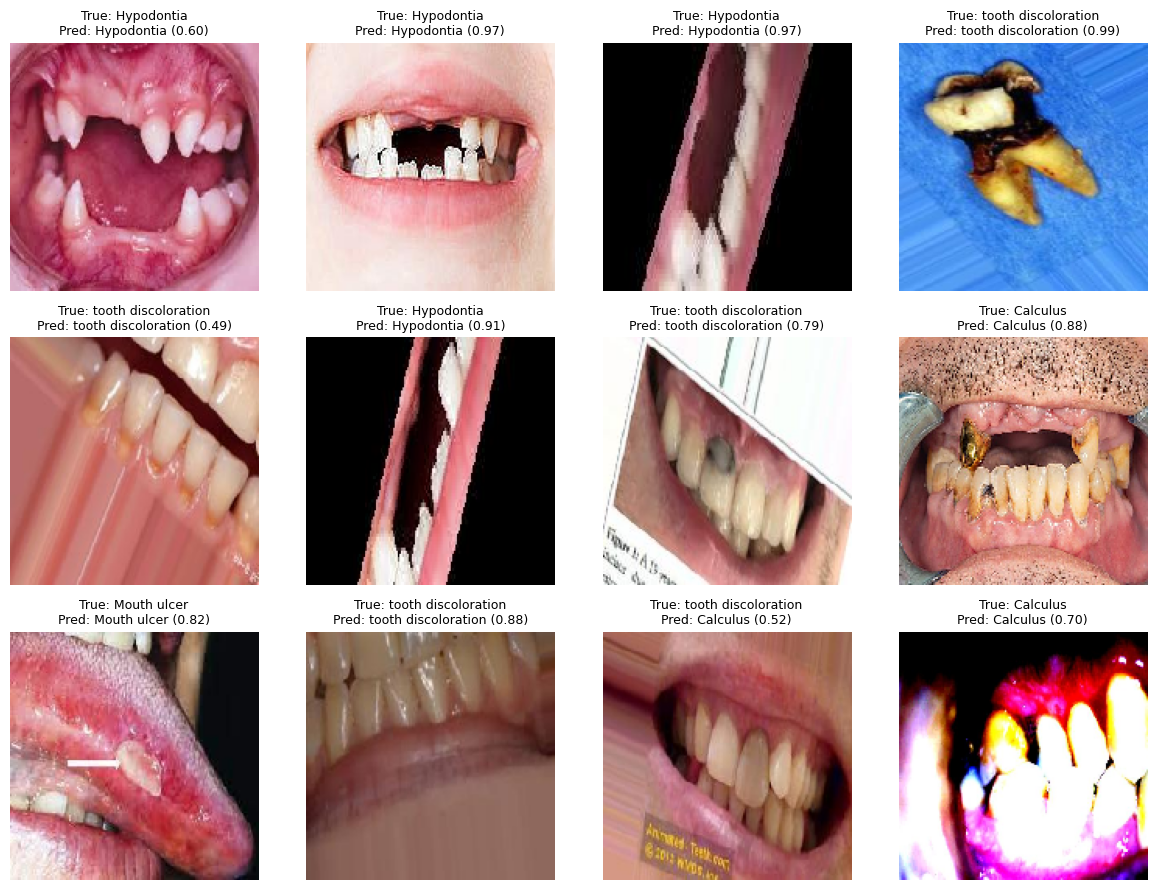

In [37]:
sample_n = min(12, len(test_df))
sample_df = test_df.sample(sample_n, random_state=SEED).reset_index(drop=True)

sample_ds = make_dataset(sample_df)
sample_probs = best_model.predict(sample_ds, verbose=0)
sample_preds = sample_probs.argmax(axis=1)
sample_conf = sample_probs.max(axis=1)

plt.figure(figsize=(12, 9))

for i, row in sample_df.iterrows():
    image = keras.utils.load_img(row["filepath"], target_size=IMG_SIZE)
    true_name = row["label"]
    pred_name = index_to_class[int(sample_preds[i])]
    conf = float(sample_conf[i])

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {true_name}\nPred: {pred_name} ({conf:.2f})",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


## 23. Save Metrics and Model Artifacts

In [38]:
OUTPUT_DIR = Path("/kaggle/working/oral_image_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save best model
FINAL_MODEL_PATH = OUTPUT_DIR / "oral_custom_cnn_best.keras"
best_model.save(FINAL_MODEL_PATH)

# Save metrics
metrics_summary.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
report_df.to_csv(OUTPUT_DIR / "classification_report.csv")
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(OUTPUT_DIR / "confusion_matrix.csv")

# Save class mapping
pd.DataFrame(
    [
        {"class_id": idx, "class_name": name}
        for idx, name in index_to_class.items()
    ]
).to_csv(OUTPUT_DIR / "class_mapping.csv", index=False)

# Save training history
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p)


Saved files:
- /kaggle/working/oral_image_outputs/class_mapping.csv
- /kaggle/working/oral_image_outputs/classification_report.csv
- /kaggle/working/oral_image_outputs/confusion_matrix.csv
- /kaggle/working/oral_image_outputs/oral_custom_cnn_best.keras
- /kaggle/working/oral_image_outputs/test_metrics.csv
- /kaggle/working/oral_image_outputs/training_history.csv


## 24. Optional: Export to TensorFlow Lite

This is not required for the academic classification experiment. Turn it on only if you need a deployment-format model.


In [39]:
EXPORT_TFLITE = False

if EXPORT_TFLITE:
    converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
    tflite_model = converter.convert()

    tflite_path = OUTPUT_DIR / "oral_custom_cnn.tflite"
    tflite_path.write_bytes(tflite_model)

    print("Saved:", tflite_path)
else:
    print("TFLite export skipped.")


TFLite export skipped.


## 25. Final Notes

This notebook now uses a **custom CNN trained from scratch** and therefore does not require Internet access or pretrained weights.

For an academic project, the key results to report are:

- Train/validation accuracy and loss curves
- Held-out test accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Per-class Precision/Recall/F1
- Confusion matrix
- Effect of class weights on the imbalanced dataset

If performance is too low, the first simple improvements to try are:
1. Increase `EPOCHS` from 20 to 30.
2. Increase `IMG_SIZE` from `(160, 160)` to `(224, 224)`.
3. Adjust augmentation strength.
4. Add one more convolution block only if necessary.
